# Example of how we will perform inference with the autoencoder in production

idea of this notebook : it provides some insight into the API (FastAPI or otherwise) that we’ll be deploying to production, and how it will perform.

# Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')
import sys
from pathlib import Path

import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

from IPython.display import display

project_root = Path.cwd().parent 
sys.path.append(str(project_root))

from src.fink_api_anomaly_detection.models import Autoencoder


from src.fink_api_anomaly_detection.data.raw_logs import ls_log_files
from src.fink_api_anomaly_detection.preprocess.nginx_logs.access_logs import build_access_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.error_logs import build_error_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.geo_logs import build_geo_dataframe
from src.fink_api_anomaly_detection.features.nginx_logs import build_temporal_features, build_feature_subsets


DATA_DIR = project_root / "data" / "nginx_test_logs"
print(f"Test Dataset directory: {DATA_DIR.resolve()}")

Test Dataset directory: /home/machter-l/fink-api-forecasting-anomaly-detection/data/nginx_test_logs


for this example, we take 2 days (17/10 00H to 19/10 00H) of test data (not seen by the model ):

In [2]:
access_files = ls_log_files(DATA_DIR, "access-logs")
geo_files = ls_log_files(DATA_DIR, "geo-logs")
error_files = ls_log_files(DATA_DIR, "error-logs")

access_df = build_access_dataframe(access_files)
geo_df = build_geo_dataframe(geo_files)
errors_df = build_error_dataframe(error_files)

print(f"access_df.shape: {access_df.shape}")
print(f"geo_df.shape: {geo_df.shape}")
print(f"errors_df.shape: {errors_df.shape}")

features_df = build_temporal_features(access_df, geo_df, errors_df)
features_df = features_df[:-1]  # Remove last row to avoid 2026-10-17 00:00:00+00:00 last value no (no in 1-14 days) in features
print(f"Feature table shape: {features_df.shape}")
print(f"Time span: {features_df['timestamp'].min()} to {features_df['timestamp'].max()}")
display(features_df.head())
display(features_df.tail())

access_df.shape: (109289, 16)
geo_df.shape: (109289, 6)
errors_df.shape: (206, 17)
Feature table shape: (575, 24)
Time span: 2026-10-17 00:00:00+00:00 to 2026-10-18 23:50:00+00:00


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_broken_pipe_count,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
0,2026-10-17 00:00:00+00:00,36,4,32,0,0,0.0,0.0,9,438802,...,0,4,0.611111,0,36,0,10,0.0,0.0,0.0
1,2026-10-17 00:05:00+00:00,78,3,75,0,0,0.0,0.0,8,1017603,...,0,3,0.666667,0,78,0,6,42.0,0.0,0.0
2,2026-10-17 00:10:00+00:00,592,4,588,0,1,0.0,0.001689,13,121392638,...,0,4,0.967905,0,592,0,10,514.0,0.001689,1.0
3,2026-10-17 00:15:00+00:00,596,2,594,0,0,0.0,0.0,7,147374492,...,0,3,0.954698,0,596,0,5,4.0,-0.001689,-1.0
4,2026-10-17 00:20:00+00:00,618,4,614,0,1,0.0,0.001618,10,137722856,...,1,5,0.972492,0,618,0,10,22.0,0.001618,1.0


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_broken_pipe_count,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
570,2026-10-18 23:30:00+00:00,88,37,51,0,0,0.0,0.0,10,3099467,...,0,3,0.511364,0,88,0,28,24.0,0.0,0.0
571,2026-10-18 23:35:00+00:00,79,39,40,0,0,0.0,0.0,7,4549132,...,0,3,0.556962,0,79,0,16,-9.0,0.0,0.0
572,2026-10-18 23:40:00+00:00,45,16,29,1,1,0.022222,0.022222,12,3313264,...,0,4,0.533333,0,44,1,16,-34.0,0.022222,0.0
573,2026-10-18 23:45:00+00:00,67,5,62,0,0,0.0,0.0,7,915846,...,0,3,0.791045,0,67,0,8,22.0,-0.022222,0.0
574,2026-10-18 23:50:00+00:00,23,9,14,0,0,0.0,0.0,9,269994,...,0,3,0.521739,0,23,0,13,-44.0,0.0,0.0


## Loading the autoencoder (trained model)

In [3]:
PATH_TO_MODEL = project_root / "artifacts" / "ae"
ae = Autoencoder().load(PATH_TO_MODEL)

2026-11-02 10:52:29.170159: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-02 10:52:29.170414: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-02 10:52:29.206963: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-11-02 10:52:30.278976: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To tur

we can also keep features names used by model, so that exactly the same thing is passed to it for inference:

In [4]:
features = ae.feature_names_

Inference (predictions) with threshold (0.3608 drawn from the conclusions of NB 05):

In [5]:
X = features_df[features].copy()

THRESHOLD = 0.3608
predictions = ae.predict(X, threshold=THRESHOLD)

print(predictions.value_counts(normalize=True)*100)
print(f"Anomalies detected: {predictions.sum()} out of {len(predictions)} ({predictions.sum()/len(predictions)*100:.2f}%)")

is_anomaly
False    88.695652
True     11.304348
Name: proportion, dtype: float64
Anomalies detected: 65 out of 575 (11.30%)


we can plot some feature with the anomalous windows highlighted in red:

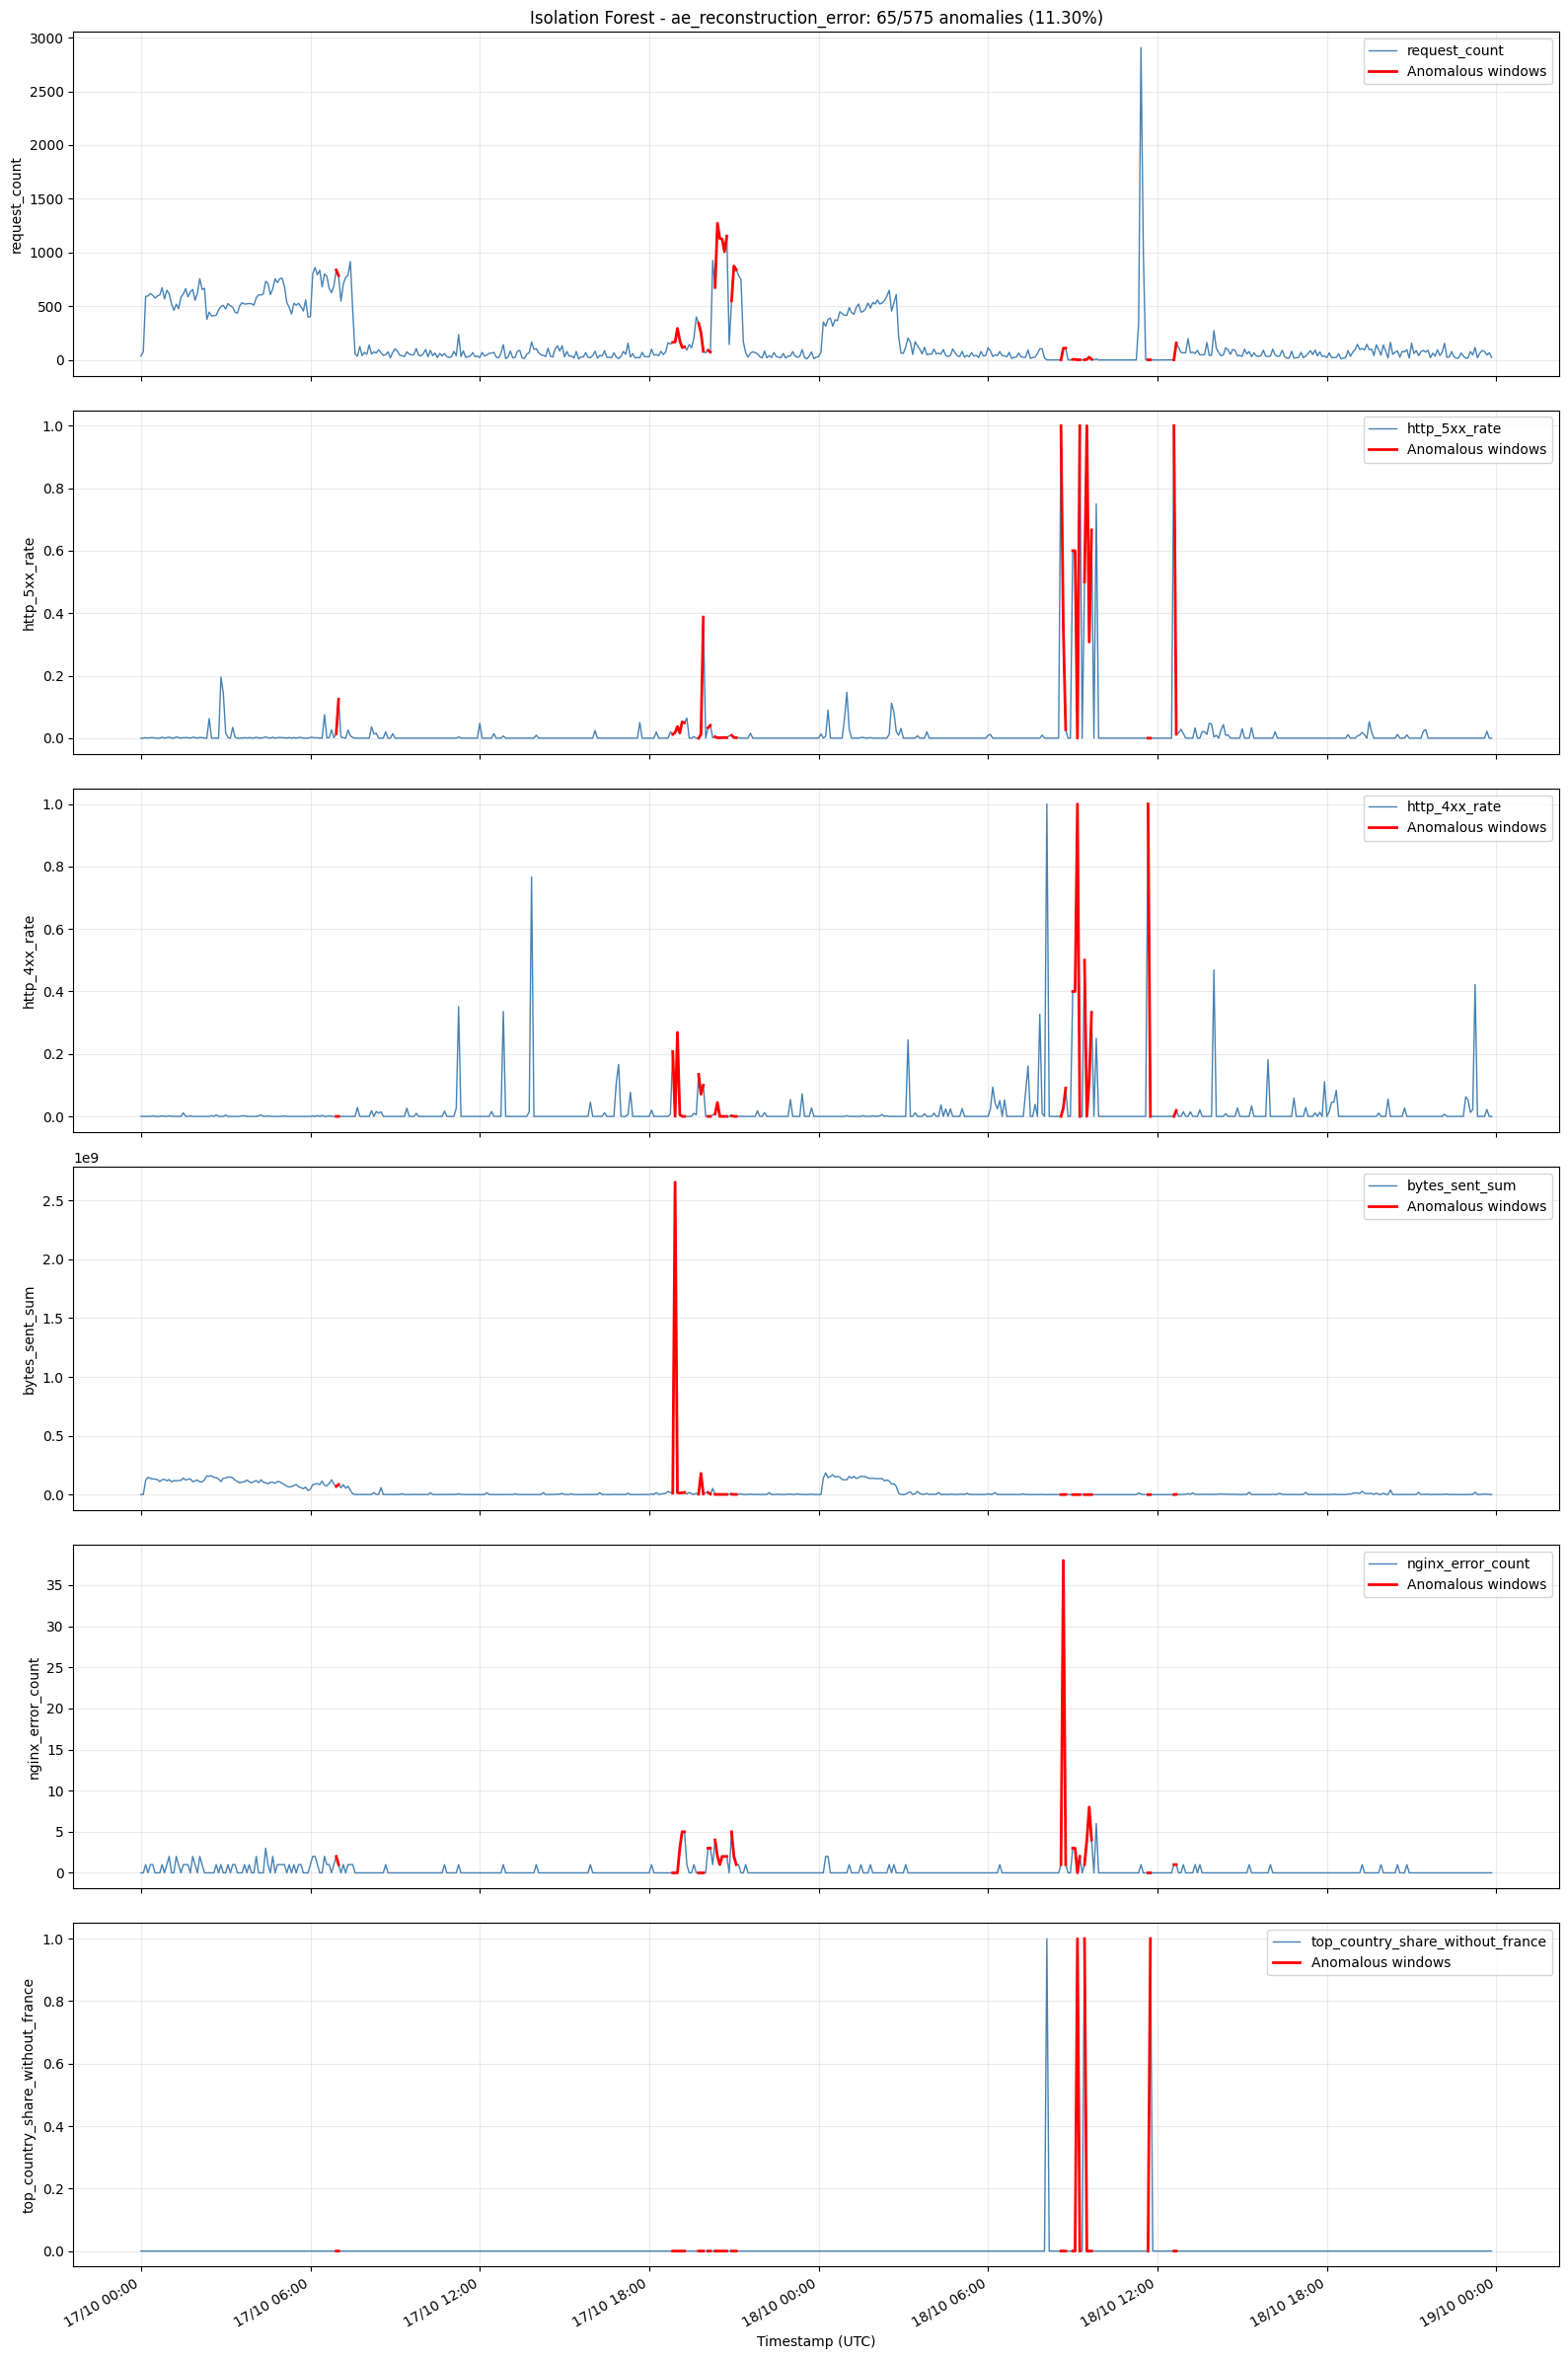

(<Figure size 1600x2400 with 6 Axes>,
 array([<Axes: title={'center': 'Isolation Forest - ae_reconstruction_error: 65/575 anomalies (11.30%)'}, ylabel='request_count'>,
        <Axes: ylabel='http_5xx_rate'>, <Axes: ylabel='http_4xx_rate'>,
        <Axes: ylabel='bytes_sent_sum'>,
        <Axes: ylabel='nginx_error_count'>,
        <Axes: xlabel='Timestamp (UTC)', ylabel='top_country_share_without_france'>],
       dtype=object))

In [7]:
from src.fink_api_anomaly_detection.utils.plot_utils import plot_anomaly_features


plot_anomaly_features(
    eval_results=pd.DataFrame(predictions),
    feature_name="ae_reconstruction_error",
    features_df=features_df,
    eval_index=features_df.index, # plot on eval period
    features_to_plot=["request_count", "http_5xx_rate", "http_4xx_rate", "bytes_sent_sum", "nginx_error_count", "top_country_share_without_france"],
)



We can clearly see that, when plotting the anomalies over time and against several features (request count, HTTP 5xx rate, etc.), the windows flagged by the model as anomalous -- 65 out of 575 windows (11.30%) -- are concentrated in a few periods across the test period.

For example:

- **17/10, from approsimately 19:45 to 21:00:** The graphs show an increase in 5xx errors (and some 4xx errors). The most significant indicator, however, is `bytesent_sum`, which reaches a very high value (its maximum).

- **18/10, from approximately 09:00 to 10:00:** All requests appear to come from the same country (excluding France from the count), which accounts for the entire traffic share (share = 1). This coincides with a large number of server-side Nginx errors. so we can suspect automated bot requests originating from datacenters.


for example , let's take some statstic from 18/10, between 09:00 to 10:00 : 

In [12]:
df_with_anomalies = features_df.copy()
df_with_anomalies["anomaly_pred"] = predictions.values

In [38]:
df_18_10_9_10 = df_with_anomalies.loc[
        df_with_anomalies["anomaly_pred"]  & df_with_anomalies["timestamp"].between(pd.Timestamp("2026-10-18 09:00:00+00:00"), pd.Timestamp("2026-10-18 10:00:00+00:00"), inclusive="left")
    ]

display(df_18_10_9_10)

display(df_18_10_9_10.describe())

,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta,anomaly_pred
396,2026-10-18 09:00:00+00:00,5,1,4,2,3,0.4,0.6,5,501,...,3,0.600000,0,4,1,3,5.0,0.6,3.0,True
397,2026-10-18 09:05:00+00:00,5,1,3,2,3,0.4,0.6,4,658,...,4,0.400000,0,4,1,3,0.0,0.0,0.0,True
398,2026-10-18 09:10:00+00:00,1,1,0,1,0,1.0,0.0,1,0,...,1,1.000000,1,0,1,1,-4.0,-0.6,-3.0,True
399,2026-10-18 09:15:00+00:00,2,0,2,0,2,0.0,1.0,2,334,...,1,1.000000,0,2,0,1,1.0,1.0,2.0,True
401,2026-10-18 09:25:00+00:00,2,0,2,1,1,0.5,0.5,2,167,...,2,0.500000,1,2,0,2,2.0,0.5,1.0,True
402,2026-10-18 09:30:00+00:00,4,0,4,0,4,0.0,1.0,4,668,...,1,1.000000,0,4,0,1,2.0,0.5,3.0,True
403,2026-10-18 09:35:00+00:00,26,4,22,3,8,0.115385,0.307692,11,422795,...,6,0.615385,0,24,2,7,22.0,-0.692308,4.0,True
404,2026-10-18 09:40:00+00:00,6,1,5,2,4,0.333333,0.666667,6,668,...,3,0.500000,0,6,0,4,-20.0,0.358974,-4.0,True
406,2026-10-18 09:50:00+00:00,8,1,7,2,6,0.25,0.75,6,1002,...,3,0.750000,0,8,0,3,8.0,0.75,6.0,True


,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,nginx_error_count,...,nginx_broken_pipe_count,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
count,9.000000,9.000000,9.000000,9.000000,9.000000,9.0,9.0,9.000000,9.000000,9.000000,...,9.0,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.0,9.000000
mean,6.555556,1.000000,5.444444,1.444444,3.444444,0.333191,0.602707,4.555556,47421.444444,3.444444,...,0.0,2.666667,0.707265,0.222222,6.000000,0.555556,2.777778,1.777778,0.268519,1.333333
std,7.617597,1.224745,6.521333,1.013794,2.455153,0.30777,0.316686,3.004626,140765.403841,2.455153,...,0.0,1.658312,0.239579,0.440959,7.141428,0.726483,1.922094,11.008835,0.58542,3.240370
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,1.000000,0.000000,0.000000,...,0.0,1.000000,0.400000,0.000000,0.000000,0.000000,1.000000,-20.000000,-0.692308,-4.000000
25%,2.000000,0.000000,2.000000,1.000000,2.000000,0.115385,0.5,2.000000,334.000000,2.000000,...,0.0,1.000000,0.500000,0.000000,2.000000,0.000000,1.000000,0.000000,0.0,0.000000
50%,5.000000,1.000000,4.000000,2.000000,3.000000,0.333333,0.6,4.000000,658.000000,3.000000,...,0.0,3.000000,0.615385,0.000000,4.000000,0.000000,3.000000,2.000000,0.5,2.000000
75%,6.000000,1.000000,5.000000,2.000000,4.000000,0.4,0.75,6.000000,668.000000,4.000000,...,0.0,3.000000,1.000000,0.000000,6.000000,1.000000,3.000000,5.000000,0.6,3.000000
max,26.000000,4.000000,22.000000,3.000000,8.000000,1.0,1.0,11.000000,422795.000000,8.000000,...,0.0,6.000000,1.000000,1.000000,24.000000,2.000000,7.000000,22.000000,1.0,6.000000


The consecutive 9  windows flagged (from 2026-10-18 09:00 to 2026-10-18 09:50) as anomalous by the model contain relatively few requests - around 5 or 6 req per window on average. However, the server-side 5xx error rate is high: on average, about 60% of requests receive a server error, corresponding to roughly 3 or 4 Nginx errors per window.

This pattern may indicate high API latency or a potential service outage, as the requests are directed to the `/api/v1` endpoint. Overall, this preliminary analysis suggests that the autoencoder, trained on data assumed to represent normal behavior, is successfully identifying unusual patterns. 

## Conclusion 

These results support deploying the model to monitor incoming traffic. When it flags a window with a high reconstruction error (> THRESHOLD), so anomaly detected, it could send an alert by email or Slack, including an automatically generated summary of the anomalous window. A normalized anomaly score (0-1 from normalised MSE recons error) could also indicate severity -- for example, **Low** (<0.4), **Medium** (0.4–<0.7), and **High** (≥0.7).

**Example alert**  
**Window (5min logs):** 2026-10-18 09:00–09:05 UTC  
**Severity:** High (anomaly score: 0.82)  
**Summary**: 5 requests over the window; HTTP 5xx error rate: 60%; Nginx errors: 3/5; top-country traffic share (excluding France): 100%.